### Import libraries:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

### Load the feature adoption dataset:

In [2]:
df_feature_adoption = pd.read_csv("../data/feature_adoption.csv")

### Understand the dataset:

In [3]:
df_feature_adoption.head()

,feature_name,total_adopting_users,total_users,total_usage_count,adoption_rate_percentage,average_usage_per_adopting_user,average_usage_per_record,first_adoption_date,latest_usage_date,adoption_rank
0,Analytics Dashboard,2945,10000,737665,29.45,250.48,250.48,2024-01-27 00:00:00+00:00,2026-11-12 00:00:00+00:00,1
1,Rate Limiting,2869,10000,705089,28.69,245.76,245.76,2024-01-17 00:00:00+00:00,2026-11-15 00:00:00+00:00,4
2,API Documentation,2873,10000,724121,28.73,252.04,252.04,2024-01-28 00:00:00+00:00,2026-11-15 00:00:00+00:00,3
3,Webhooks,2913,10000,718339,29.13,246.60,246.60,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,2
4,API Authentication,2796,10000,678096,27.96,242.52,242.52,2024-01-22 00:00:00+00:00,2026-11-15 00:00:00+00:00,7


In [4]:
df_feature_adoption.shape

(7, 10)

In [5]:
df_feature_adoption.columns

Index(['feature_name', 'total_adopting_users', 'total_users',
       'total_usage_count', 'adoption_rate_percentage',
       'average_usage_per_adopting_user', 'average_usage_per_record',
       'first_adoption_date', 'latest_usage_date', 'adoption_rank'],
      dtype='str')

In [6]:
df_feature_adoption.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   feature_name                     7 non-null      str    
 1   total_adopting_users             7 non-null      int64  
 2   total_users                      7 non-null      int64  
 3   total_usage_count                7 non-null      int64  
 4   adoption_rate_percentage         7 non-null      float64
 5   average_usage_per_adopting_user  7 non-null      float64
 6   average_usage_per_record         7 non-null      float64
 7   first_adoption_date              7 non-null      str    
 8   latest_usage_date                7 non-null      str    
 9   adoption_rank                    7 non-null      int64  
dtypes: float64(3), int64(4), str(3)
memory usage: 1.1 KB


In [7]:
df_feature_adoption.describe(include="all")

,feature_name,total_adopting_users,total_users,total_usage_count,adoption_rate_percentage,average_usage_per_adopting_user,average_usage_per_record,first_adoption_date,latest_usage_date,adoption_rank
count,7,7.000000,7.0,7.000000,7.000000,7.000000,7.000000,7,7,7.000000
unique,7,NaN,NaN,NaN,NaN,NaN,NaN,6,2,NaN
top,Analytics Dashboard,NaN,NaN,NaN,NaN,NaN,NaN,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,2,6,NaN
mean,NaN,2863.000000,10000.0,712152.571429,28.630000,248.727143,248.727143,NaN,NaN,4.000000
std,NaN,54.726593,0.0,19475.548078,0.547266,3.940138,3.940138,NaN,NaN,2.160247
min,NaN,2796.000000,10000.0,678096.000000,27.960000,242.520000,242.520000,NaN,NaN,1.000000
25%,NaN,2822.500000,10000.0,702617.500000,28.225000,246.180000,246.180000,NaN,NaN,2.500000
50%,NaN,2869.000000,10000.0,718339.000000,28.690000,249.870000,249.870000,NaN,NaN,4.000000
75%,NaN,2893.000000,10000.0,722866.500000,28.930000,251.260000,251.260000,NaN,NaN,5.500000


### Identify the adoption metrics:

#### check the exact column names

In [8]:
for column in df_feature_adoption.columns:
    print(column)

feature_name
total_adopting_users
total_users
total_usage_count
adoption_rate_percentage
average_usage_per_adopting_user
average_usage_per_record
first_adoption_date
latest_usage_date
adoption_rank


#### inspect the complete dataset:

In [9]:
display(df_feature_adoption)

,feature_name,total_adopting_users,total_users,total_usage_count,adoption_rate_percentage,average_usage_per_adopting_user,average_usage_per_record,first_adoption_date,latest_usage_date,adoption_rank
0,Analytics Dashboard,2945,10000,737665,29.45,250.48,250.48,2024-01-27 00:00:00+00:00,2026-11-12 00:00:00+00:00,1
1,Rate Limiting,2869,10000,705089,28.69,245.76,245.76,2024-01-17 00:00:00+00:00,2026-11-15 00:00:00+00:00,4
2,API Documentation,2873,10000,724121,28.73,252.04,252.04,2024-01-28 00:00:00+00:00,2026-11-15 00:00:00+00:00,3
3,Webhooks,2913,10000,718339,29.13,246.60,246.60,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,2
4,API Authentication,2796,10000,678096,27.96,242.52,242.52,2024-01-22 00:00:00+00:00,2026-11-15 00:00:00+00:00,7
5,SDK Integration,2843,10000,721612,28.43,253.82,253.82,2024-01-24 00:00:00+00:00,2026-11-15 00:00:00+00:00,5
6,API Monitoring,2802,10000,700146,28.02,249.87,249.87,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,6


### Rank features by adoption:

In [10]:
adoption_ranking = df_feature_adoption.sort_values(
    by="total_adopting_users",
    ascending=False
)

display(adoption_ranking)

,feature_name,total_adopting_users,total_users,total_usage_count,adoption_rate_percentage,average_usage_per_adopting_user,average_usage_per_record,first_adoption_date,latest_usage_date,adoption_rank
0,Analytics Dashboard,2945,10000,737665,29.45,250.48,250.48,2024-01-27 00:00:00+00:00,2026-11-12 00:00:00+00:00,1
3,Webhooks,2913,10000,718339,29.13,246.60,246.60,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,2
2,API Documentation,2873,10000,724121,28.73,252.04,252.04,2024-01-28 00:00:00+00:00,2026-11-15 00:00:00+00:00,3
1,Rate Limiting,2869,10000,705089,28.69,245.76,245.76,2024-01-17 00:00:00+00:00,2026-11-15 00:00:00+00:00,4
5,SDK Integration,2843,10000,721612,28.43,253.82,253.82,2024-01-24 00:00:00+00:00,2026-11-15 00:00:00+00:00,5
6,API Monitoring,2802,10000,700146,28.02,249.87,249.87,2024-01-23 00:00:00+00:00,2026-11-15 00:00:00+00:00,6
4,API Authentication,2796,10000,678096,27.96,242.52,242.52,2024-01-22 00:00:00+00:00,2026-11-15 00:00:00+00:00,7


### Visualize total adopting users:

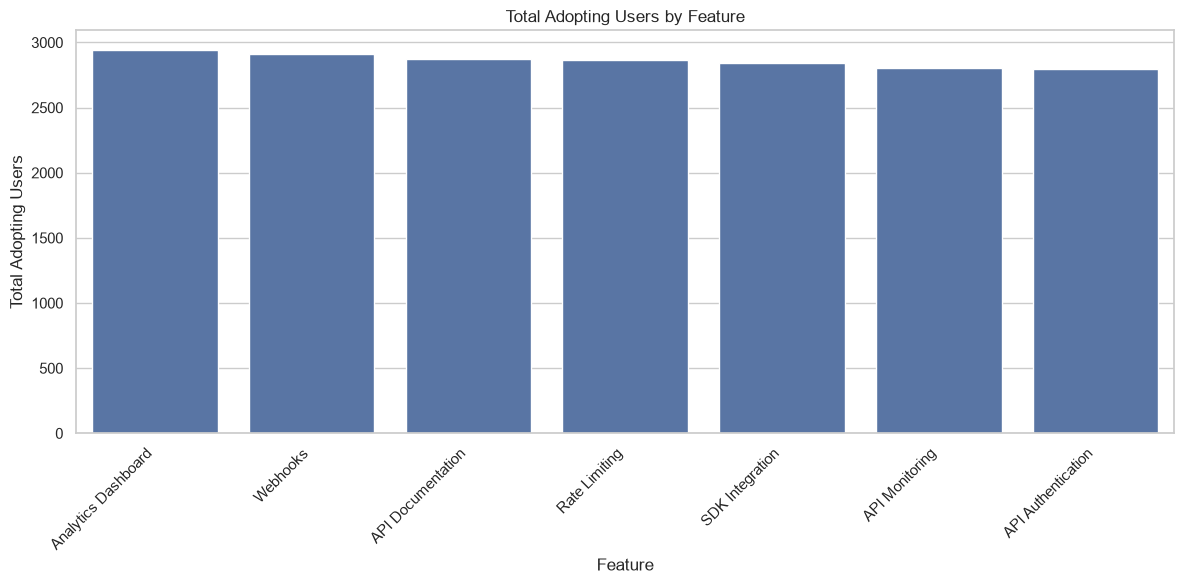

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=adoption_ranking,
    x="feature_name",
    y="total_adopting_users"
)

plt.title("Total Adopting Users by Feature")
plt.xlabel("Feature")
plt.ylabel("Total Adopting Users")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### Analyze total feature usage:

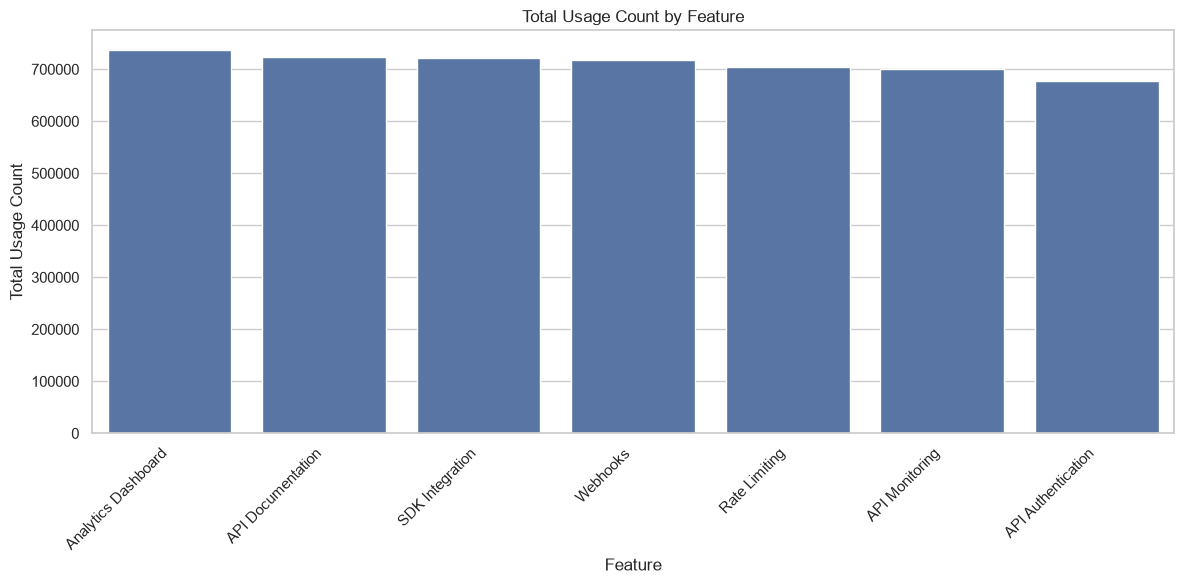

In [12]:
usage_ranking = df_feature_adoption.sort_values(
    by="total_usage_count",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=usage_ranking,
    x="feature_name",
    y="total_usage_count"
)

plt.title("Total Usage Count by Feature")
plt.xlabel("Feature")
plt.ylabel("Total Usage Count")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### Analyze adoption rate:

#### check whether the dataset contains adoption_rate_percentage

In [13]:
if "adoption_rate_percentage" in df_feature_adoption.columns:

    adoption_rate_ranking = df_feature_adoption.sort_values(
        by="adoption_rate_percentage",
        ascending=False
    )

    display(
        adoption_rate_ranking[
            ["feature_name", "adoption_rate_percentage"]
        ]
    )
else:
    print("Adoption rate column not found. Check the available columns.")

,feature_name,adoption_rate_percentage
0,Analytics Dashboard,29.45
3,Webhooks,29.13
2,API Documentation,28.73
1,Rate Limiting,28.69
5,SDK Integration,28.43
6,API Monitoring,28.02
4,API Authentication,27.96


#### If the column exists, visualize it:

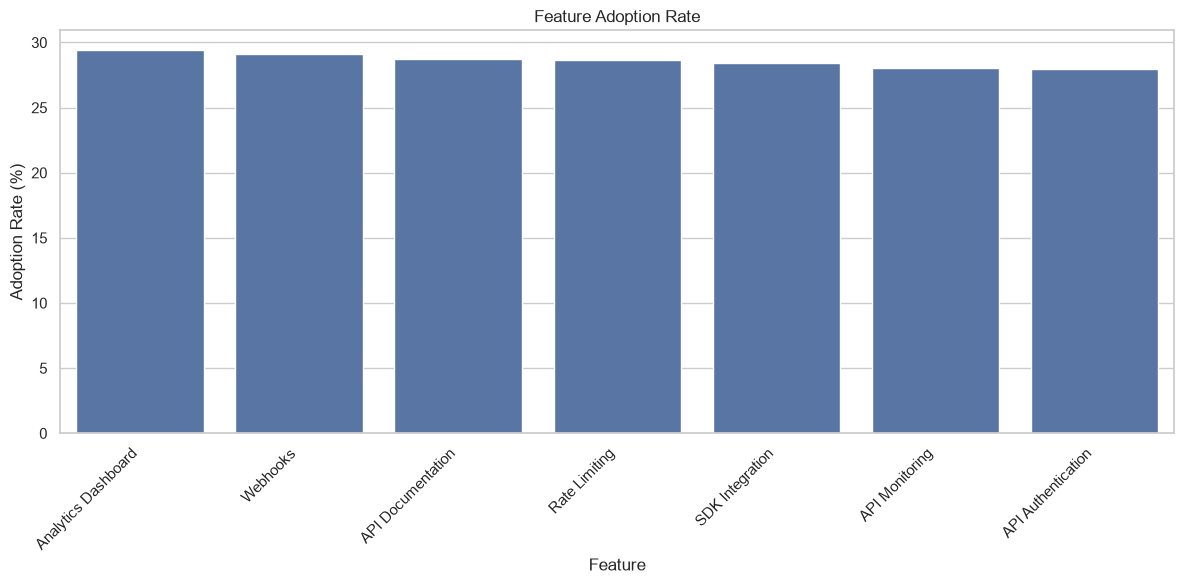

In [14]:
if "adoption_rate_percentage" in df_feature_adoption.columns:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=df_feature_adoption.sort_values(
            "adoption_rate_percentage",
            ascending=False
        ),
        x="feature_name",
        y="adoption_rate_percentage"
    )

    plt.title("Feature Adoption Rate")
    plt.xlabel("Feature")
    plt.ylabel("Adoption Rate (%)")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

### Save the adoption ranking report:

In [15]:
os.makedirs("../data", exist_ok=True)

adoption_ranking.to_csv(
    "../data/feature_adoption_ranking.csv",
    index=False
)

print("Feature adoption ranking saved successfully.")

Feature adoption ranking saved successfully.


### Save your visualizations:

In [16]:
os.makedirs("../visualizations", exist_ok=True)

In [17]:
plt.savefig(
    "../visualizations/feature_adoption_users.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [18]:
plt.savefig(
    "../visualizations/feature_usage_count.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>